In [34]:
print("Welcome to ComplainSense AI!")


Welcome to ComplainSense AI!


In [35]:
%pip install numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:

# ==========================================
# ComplainSense AI
# Cell 1: Import Essential Libraries
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

# Text processing
from sklearn.feature_extraction.text import TfidfVectorizer

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Model saving
import joblib

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("All Libraries Imported Successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

All Libraries Imported Successfully!
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [43]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Current Working Directory:
c:\Users\Newla\Downloads\Bitext_Customer_Support

Files and Folders:
['Bitext_Customer_Support.csv', 'ComplainSense_AI.ipynb', 'data', 'models']


In [44]:
import pandas as pd

df = pd.read_csv("Bitext_Customer_Support.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [45]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Columns:
['flags', 'instruction', 'category', 'intent', 'response']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   flags        26872 non-null  str  
 1   instruction  26872 non-null  str  
 2   category     26872 non-null  str  
 3   intent       26872 non-null  str  
 4   response     26872 non-null  str  
dtypes: str(5)
memory usage: 1.0 MB


In [46]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [47]:
print("Total Duplicate Rows:")
print(df.duplicated().sum())

Total Duplicate Rows:
0


In [48]:
print("Category Distribution:")
print(df["category"].value_counts())

Category Distribution:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


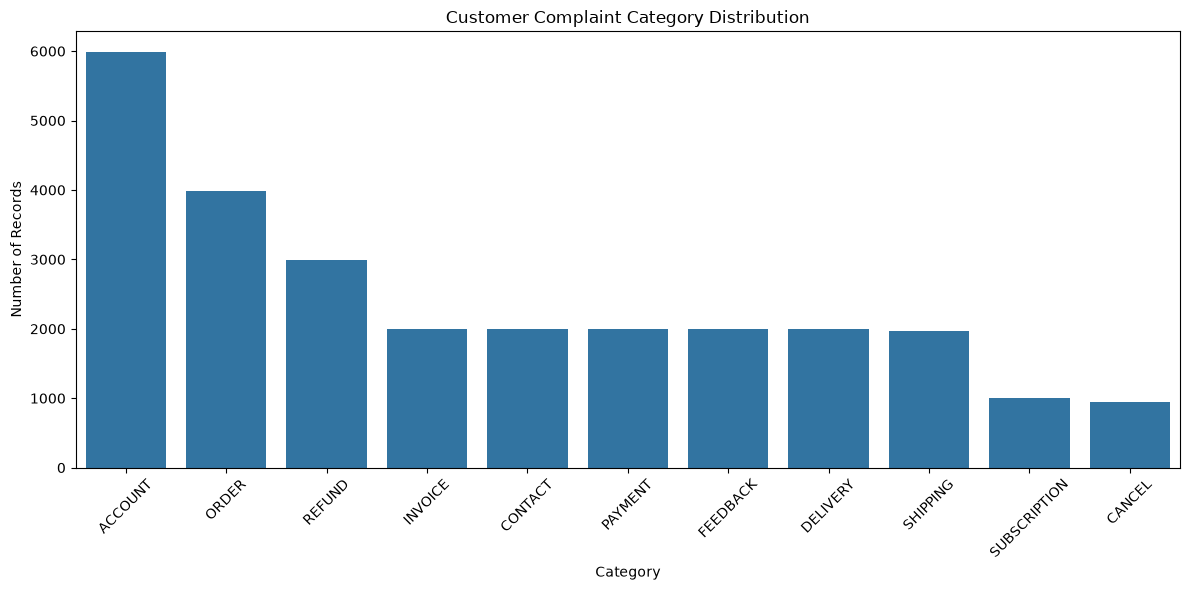

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Customer Complaint Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
print("Total Unique Intents:")
print(df["intent"].nunique())

print("\nIntent Distribution:")
print(df["intent"].value_counts())

Total Unique Intents:
27

Intent Distribution:
intent
check_invoice               1000
complaint                   1000
contact_customer_service    1000
edit_account                1000
switch_account              1000
check_payment_methods        999
contact_human_agent          999
delivery_period              999
get_invoice                  999
newsletter_subscription      999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
set_up_shipping_address      997
delete_account               995
delivery_options             995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64


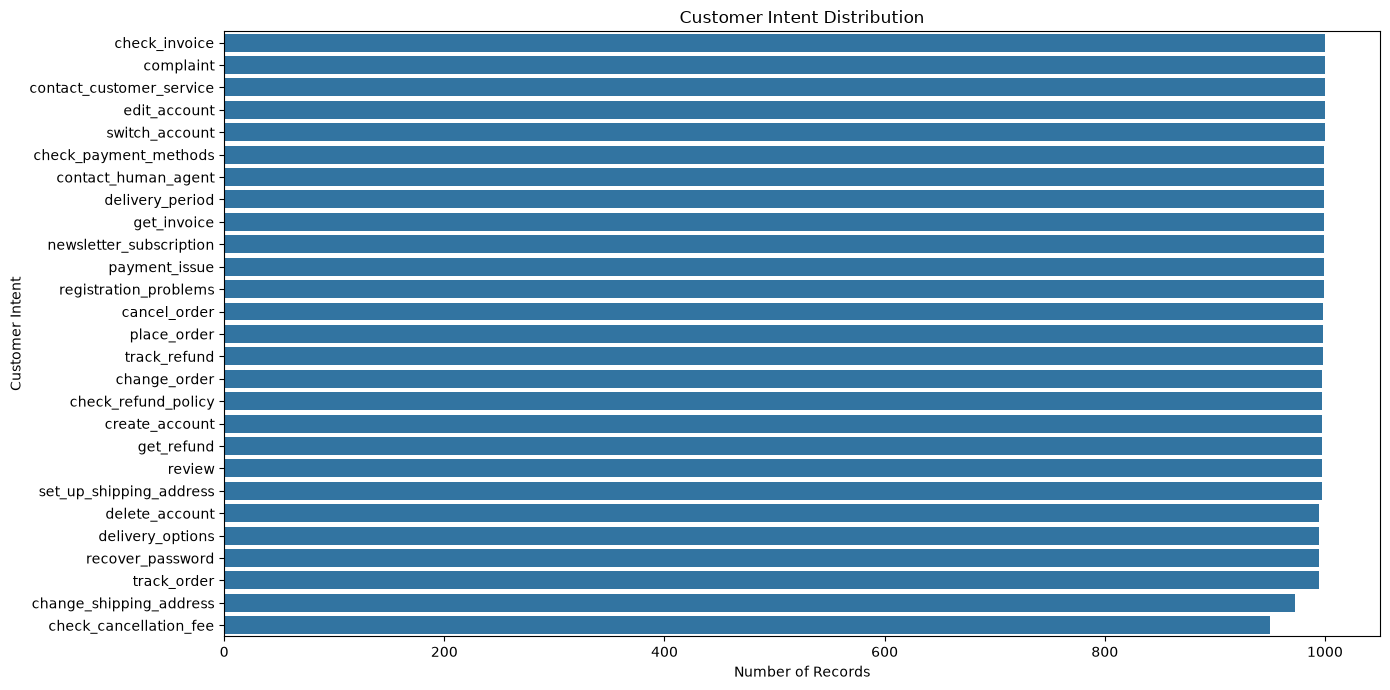

In [51]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    y="intent",
    order=df["intent"].value_counts().index
)

plt.title("Customer Intent Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Customer Intent")
plt.tight_layout()
plt.show()

In [52]:
df["text_length"] = df["instruction"].apply(
    lambda x: len(x.split())
)

print("Text Length Statistics:")
print(df["text_length"].describe())

Text Length Statistics:
count    26872.000000
mean         8.690979
std          2.605004
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         16.000000
Name: text_length, dtype: float64


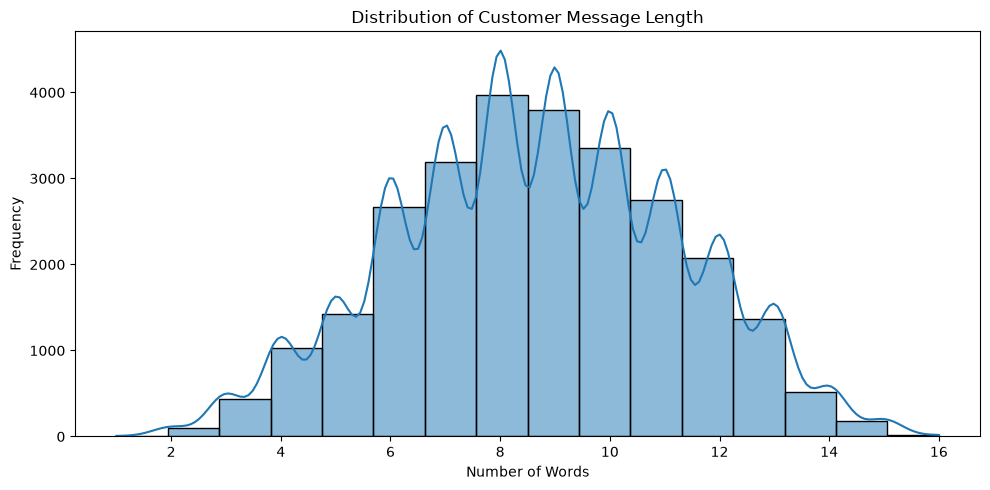

In [53]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    bins=16,
    kde=True
)

plt.title("Distribution of Customer Message Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [54]:
for i in range(10):
    print("Customer Message:", df["instruction"].iloc[i])
    print("Category:", df["category"].iloc[i])
    print("Intent:", df["intent"].iloc[i])
    print("-" * 60)

Customer Message: question about cancelling order {{Order Number}}
Category: ORDER
Intent: cancel_order
------------------------------------------------------------
Customer Message: i have a question about cancelling oorder {{Order Number}}
Category: ORDER
Intent: cancel_order
------------------------------------------------------------
Customer Message: i need help cancelling puchase {{Order Number}}
Category: ORDER
Intent: cancel_order
------------------------------------------------------------
Customer Message: I need to cancel purchase {{Order Number}}
Category: ORDER
Intent: cancel_order
------------------------------------------------------------
Customer Message: I cannot afford this order, cancel purchase {{Order Number}}
Category: ORDER
Intent: cancel_order
------------------------------------------------------------
Customer Message: can you help me cancel order {{Order Number}}?
Category: ORDER
Intent: cancel_order
----------------------------------------------------------

In [55]:
print("========== FINAL DATASET REPORT ==========")

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("Unique Categories:", df["category"].nunique())
print("Unique Intents:", df["intent"].nunique())

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDataset Columns:")
print(df.columns.tolist())

print("\n========== DATASET READY FOR NLP ==========")

========== FINAL DATASET REPORT ==========
Total Records: 26872
Total Columns: 6
Unique Categories: 11
Unique Intents: 27
Missing Values: 0
Duplicate Rows: 0

Dataset Columns:
['flags', 'instruction', 'category', 'intent', 'response', 'text_length']

========== DATASET READY FOR NLP ==========


In [56]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

df["clean_text"] = df["instruction"].apply(clean_text)

print("Original Text:")
print(df["instruction"].iloc[0])

print("\nCleaned Text:")
print(df["clean_text"].iloc[0])

Original Text:
question about cancelling order {{Order Number}}

Cleaned Text:
question about cancelling order {{order number}}


In [57]:
print("Original Messages:")
print(df["instruction"].head(10).tolist())

print("\nCleaned Messages:")
print(df["clean_text"].head(10).tolist())

print("\nTotal Cleaned Records:")
print(df["clean_text"].notnull().sum())

Original Messages:
['question about cancelling order {{Order Number}}', 'i have a question about cancelling oorder {{Order Number}}', 'i need help cancelling puchase {{Order Number}}', 'I need to cancel purchase {{Order Number}}', 'I cannot afford this order, cancel purchase {{Order Number}}', 'can you help me cancel order {{Order Number}}?', 'I can no longer afford order {{Order Number}}, cancel it', 'I am trying to cancel purchase {{Order Number}}', 'I have got to cancel purchase {{Order Number}}', 'i need help canceling purchase {{Order Number}}']

Cleaned Messages:
['question about cancelling order {{order number}}', 'i have a question about cancelling oorder {{order number}}', 'i need help cancelling puchase {{order number}}', 'i need to cancel purchase {{order number}}', 'i cannot afford this order, cancel purchase {{order number}}', 'can you help me cancel order {{order number}}?', 'i can no longer afford order {{order number}}, cancel it', 'i am trying to cancel purchase {{orde

In [58]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s{}]", "", text)
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

df["clean_text"] = df["instruction"].apply(clean_text)

print("Original:")
print(df["instruction"].iloc[5])

print("\nCleaned:")
print(df["clean_text"].iloc[5])

Original:
can you help me cancel order {{Order Number}}?

Cleaned:
can you help me cancel order {{order number}}


In [59]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y_category = df["category"]

X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Training Records:", len(X_train_cat))
print("Testing Records:", len(X_test_cat))

Training Records: 21497
Testing Records: 5375


In [60]:
X = df["clean_text"]
y_intent = df["intent"]

X_train_intent, X_test_intent, y_train_intent, y_test_intent = train_test_split(
    X,
    y_intent,
    test_size=0.20,
    random_state=42,
    stratify=y_intent
)

print("Training Records:", len(X_train_intent))
print("Testing Records:", len(X_test_intent))

Training Records: 21497
Testing Records: 5375


In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=40000,
    min_df=2
)

X_train_cat_tfidf = tfidf.fit_transform(X_train_cat)
X_test_cat_tfidf = tfidf.transform(X_test_cat)

print("Training TF-IDF Shape:", X_train_cat_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_cat_tfidf.shape)

Training TF-IDF Shape: (21497, 5210)
Testing TF-IDF Shape: (5375, 5210)


In [62]:
from sklearn.linear_model import LogisticRegression

category_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

category_model.fit(X_train_cat_tfidf, y_train_cat)

print("Category Model Trained Successfully!")

Category Model Trained Successfully!


In [63]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_cat = category_model.predict(X_test_cat_tfidf)

accuracy = accuracy_score(y_test_cat, y_pred_cat)

print("Category Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test_cat, y_pred_cat))

Category Model Accuracy: 99.72093023255813 %

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.99      1.00      1.00      1197
      CANCEL       0.99      1.00      0.99       190
     CONTACT       1.00      1.00      1.00       400
    DELIVERY       1.00      1.00      1.00       399
    FEEDBACK       1.00      1.00      1.00       399
     INVOICE       1.00      1.00      1.00       400
       ORDER       1.00      1.00      1.00       798
     PAYMENT       1.00      0.98      0.99       400
      REFUND       1.00      1.00      1.00       598
    SHIPPING       1.00      0.99      0.99       394
SUBSCRIPTION       1.00      1.00      1.00       200

    accuracy                           1.00      5375
   macro avg       1.00      1.00      1.00      5375
weighted avg       1.00      1.00      1.00      5375



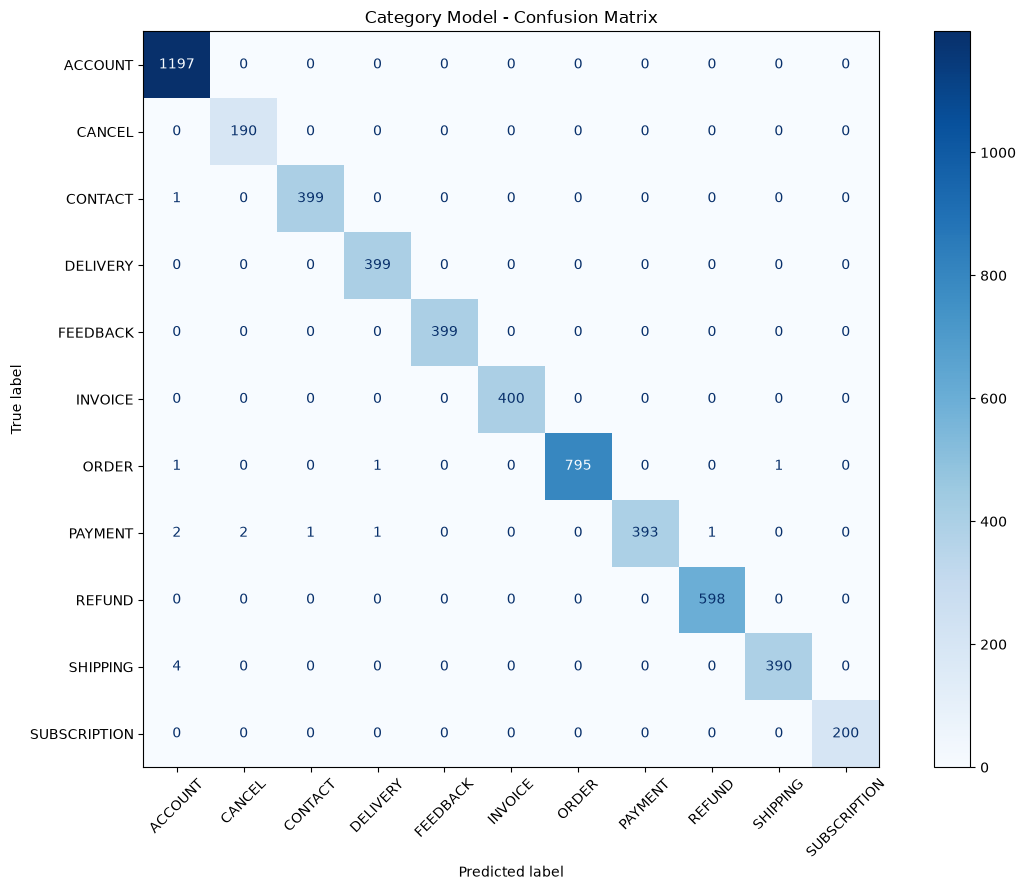

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_cat, y_pred_cat)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=category_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 9))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Category Model - Confusion Matrix")
plt.tight_layout()
plt.show()

In [65]:
X_train_intent_tfidf = tfidf.transform(X_train_intent)
X_test_intent_tfidf = tfidf.transform(X_test_intent)

print("Intent Training Shape:", X_train_intent_tfidf.shape)
print("Intent Testing Shape:", X_test_intent_tfidf.shape)


Intent Training Shape: (21497, 5210)
Intent Testing Shape: (5375, 5210)


In [66]:
intent_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

intent_model.fit(X_train_intent_tfidf, y_train_intent)

print("Intent Model Trained Successfully!")

Intent Model Trained Successfully!


In [67]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_intent = intent_model.predict(X_test_intent_tfidf)

intent_accuracy = accuracy_score(y_test_intent, y_pred_intent)

print("Intent Model Accuracy:", intent_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test_intent, y_pred_intent))

Intent Model Accuracy: 99.4046511627907 %

Classification Report:
                          precision    recall  f1-score   support

            cancel_order       1.00      0.98      0.99       200
            change_order       0.97      0.98      0.97       199
 change_shipping_address       0.99      1.00      1.00       195
  check_cancellation_fee       0.99      1.00      1.00       190
           check_invoice       0.97      0.99      0.98       200
   check_payment_methods       1.00      0.99      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      0.99      0.99       200
     contact_human_agent       0.99      0.99      0.99       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      0.99       199
        delivery_options       1.00      1.00      1.00       199
         

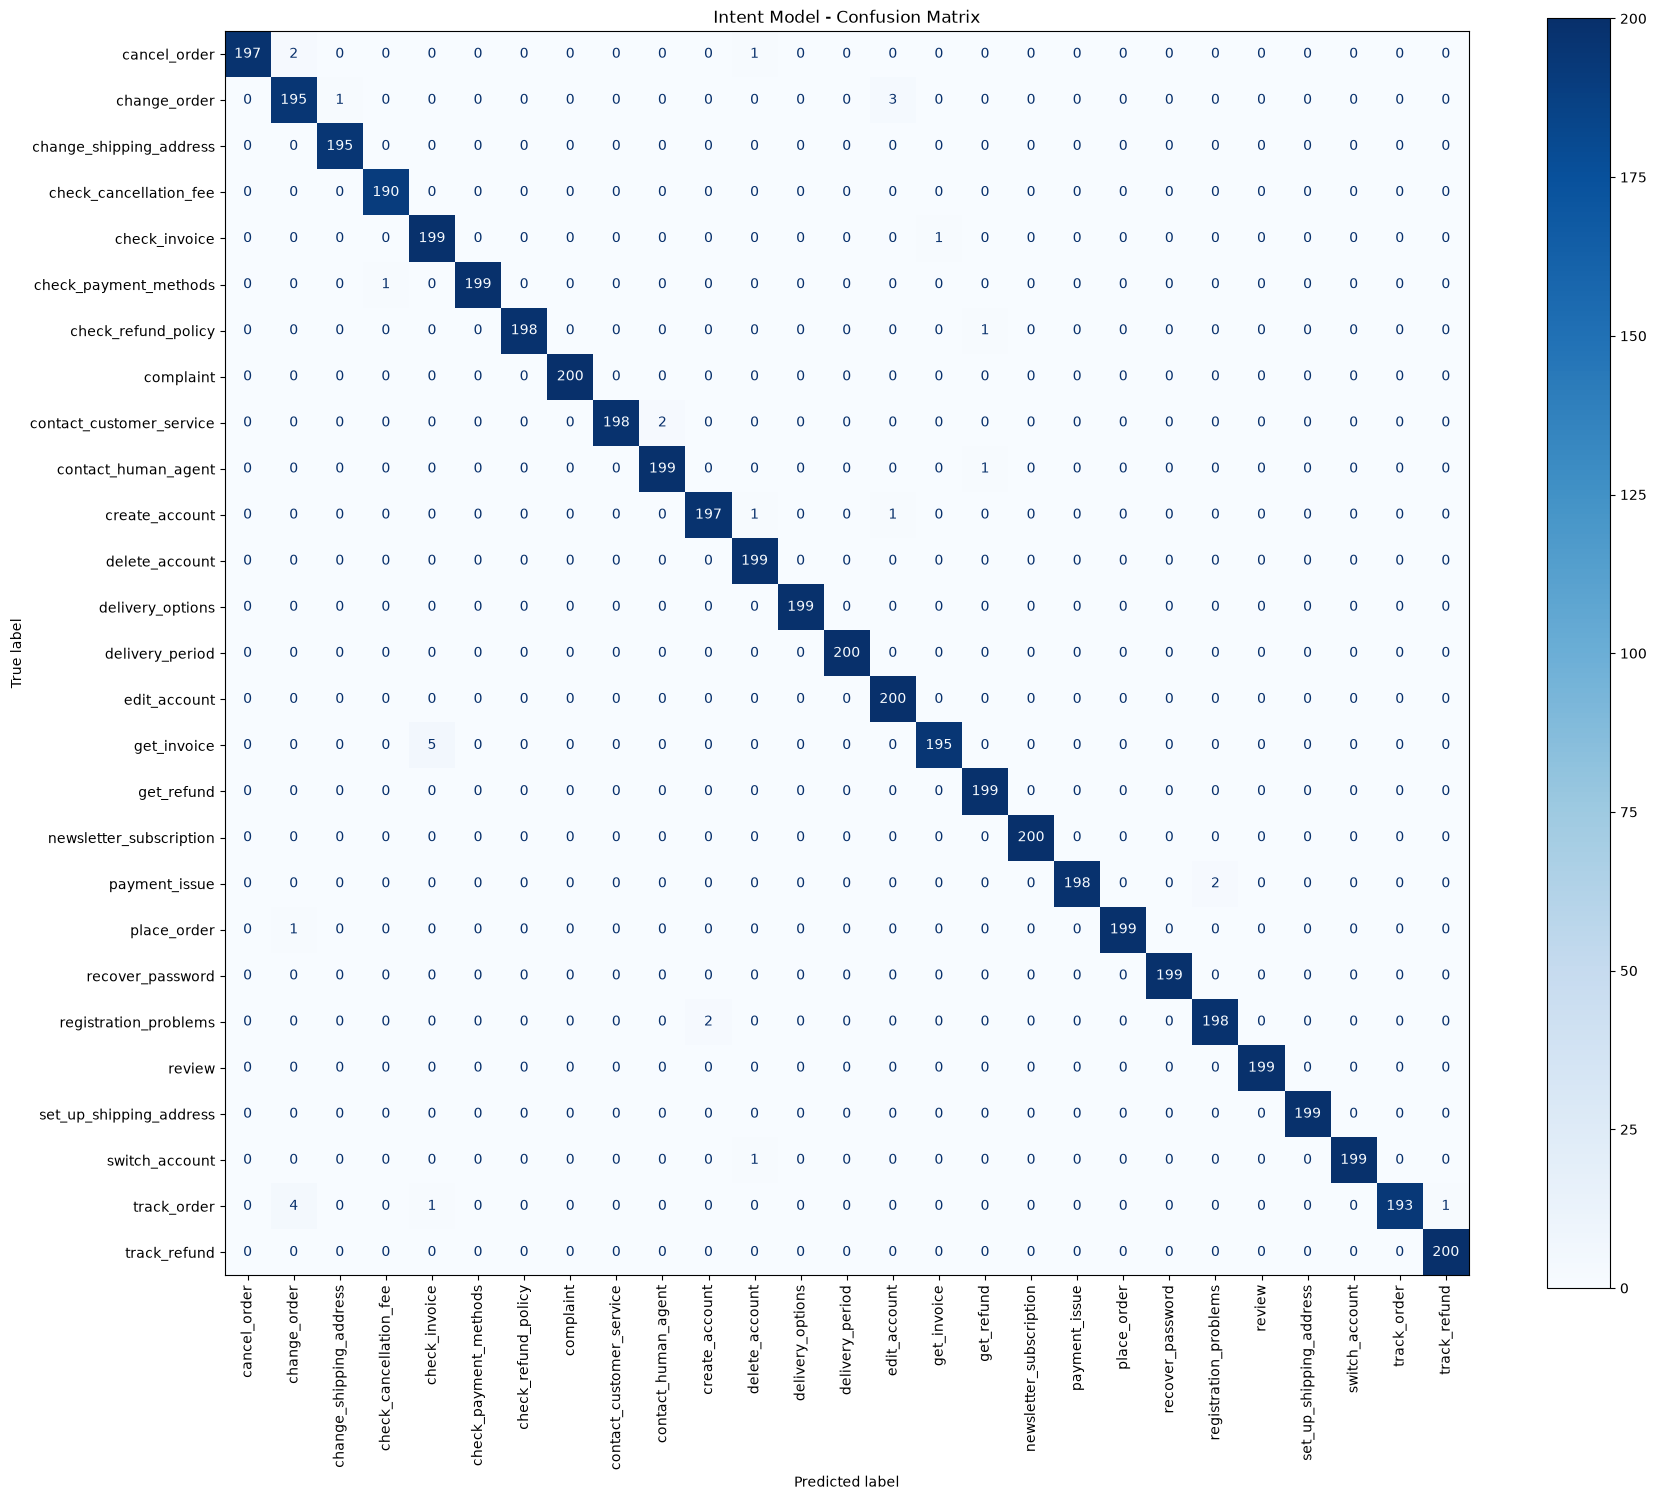

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_intent = confusion_matrix(y_test_intent, y_pred_intent)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_intent,
    display_labels=intent_model.classes_
)

fig, ax = plt.subplots(figsize=(18, 15))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)

plt.title("Intent Model - Confusion Matrix")
plt.tight_layout()
plt.show()

In [69]:
test_messages = [
    "I want to cancel my recent purchase",
    "Can you tell me where my package is?",
    "I need a copy of my payment invoice",
    "My account password is not working",
    "I want my money refunded",
    "I would like to speak with a human agent",
    "Please change my delivery address",
    "I am facing an issue while making payment"
]

clean_messages = [clean_text(msg) for msg in test_messages]

message_tfidf = tfidf.transform(clean_messages)

category_predictions = category_model.predict(message_tfidf)
intent_predictions = intent_model.predict(message_tfidf)

for message, category, intent in zip(
    test_messages,
    category_predictions,
    intent_predictions
):
    print("Customer Message:", message)
    print("Predicted Category:", category)
    print("Predicted Intent:", intent)
    print("-" * 60)

Customer Message: I want to cancel my recent purchase
Predicted Category: ORDER
Predicted Intent: cancel_order
------------------------------------------------------------
Customer Message: Can you tell me where my package is?
Predicted Category: DELIVERY
Predicted Intent: delivery_period
------------------------------------------------------------
Customer Message: I need a copy of my payment invoice
Predicted Category: PAYMENT
Predicted Intent: payment_issue
------------------------------------------------------------
Customer Message: My account password is not working
Predicted Category: ACCOUNT
Predicted Intent: recover_password
------------------------------------------------------------
Customer Message: I want my money refunded
Predicted Category: REFUND
Predicted Intent: get_refund
------------------------------------------------------------
Customer Message: I would like to speak with a human agent
Predicted Category: CONTACT
Predicted Intent: contact_human_agent
------------

In [70]:
category_probabilities = category_model.predict_proba(message_tfidf)
intent_probabilities = intent_model.predict_proba(message_tfidf)

for i, message in enumerate(test_messages):

    category_confidence = max(category_probabilities[i]) * 100
    intent_confidence = max(intent_probabilities[i]) * 100

    print("Message:", message)
    print("Category:", category_predictions[i])
    print("Category Confidence:", round(category_confidence, 2), "%")
    print("Intent:", intent_predictions[i])
    print("Intent Confidence:", round(intent_confidence, 2), "%")
    print("-" * 60)

Message: I want to cancel my recent purchase
Category: ORDER
Category Confidence: 39.08 %
Intent: cancel_order
Intent Confidence: 49.42 %
------------------------------------------------------------
Message: Can you tell me where my package is?
Category: DELIVERY
Category Confidence: 35.09 %
Intent: delivery_period
Intent Confidence: 22.95 %
------------------------------------------------------------
Message: I need a copy of my payment invoice
Category: PAYMENT
Category Confidence: 80.29 %
Intent: payment_issue
Intent Confidence: 41.64 %
------------------------------------------------------------
Message: My account password is not working
Category: ACCOUNT
Category Confidence: 89.81 %
Intent: recover_password
Intent Confidence: 58.56 %
------------------------------------------------------------
Message: I want my money refunded
Category: REFUND
Category Confidence: 81.26 %
Intent: get_refund
Intent Confidence: 75.65 %
------------------------------------------------------------
Me

In [71]:
import pandas as pd

error_analysis = pd.DataFrame({
    "Actual Intent": y_test_intent.values,
    "Predicted Intent": y_pred_intent
})

errors = error_analysis[
    error_analysis["Actual Intent"] != error_analysis["Predicted Intent"]
]

print("Total Incorrect Predictions:", len(errors))

print("\nMost Common Intent Errors:")

print(
    errors.groupby(
        ["Actual Intent", "Predicted Intent"]
    ).size().sort_values(ascending=False).head(15)
)

Total Incorrect Predictions: 32

Most Common Intent Errors:
Actual Intent             Predicted Intent       
get_invoice               check_invoice              5
track_order               change_order               4
change_order              edit_account               3
payment_issue             registration_problems      2
registration_problems     create_account             2
cancel_order              change_order               2
contact_customer_service  contact_human_agent        2
change_order              change_shipping_address    1
cancel_order              delete_account             1
check_payment_methods     check_cancellation_fee     1
check_invoice             get_invoice                1
create_account            edit_account               1
                          delete_account             1
contact_human_agent       get_refund                 1
check_refund_policy       get_refund                 1
dtype: int64


In [72]:
error_details = pd.DataFrame({
    "Customer Message": df.loc[X_test_intent.index, "instruction"].values,
    "Actual Intent": y_test_intent.values,
    "Predicted Intent": y_pred_intent
})

errors = error_details[
    error_details["Actual Intent"] != error_details["Predicted Intent"]
]

print(errors.to_string(index=False))

                                            Customer Message            Actual Intent        Predicted Intent
              I do not know how I candownload my bill #37777              get_invoice           check_invoice
                                       help creating account    registration_problems          create_account
                           am I entitled to a reimbursement?      check_refund_policy              get_refund
     I don't know what to do to speak with cusstomer service contact_customer_service     contact_human_agent
             need assistance reporting an issue with pyments            payment_issue   registration_problems
                                               I need a user           create_account            edit_account
             what do i have to do to createa premium account           create_account          delete_account
           i do not know what to do to cdheck my bill #85632            check_invoice             get_invoice
          

In [73]:
from collections import Counter
import re

all_words = []

for text in df["clean_text"]:
    words = re.findall(r"[a-z]+", text)
    all_words.extend(words)

word_counts = Counter(all_words)

print("Total Unique Words:", len(word_counts))

print("\nMost Common 30 Words:")
for word, count in word_counts.most_common(30):
    print(word, ":", count)

Total Unique Words: 2839

Most Common 30 Words:
i : 18874
to : 16400
the : 6413
help : 6319
a : 6086
account : 5400
do : 5348
can : 5274
order : 4847
my : 4774
how : 4207
need : 4059
of : 3995
me : 3661
what : 3136
want : 3110
assistance : 3005
have : 2957
number : 2953
know : 2691
with : 2553
see : 2545
check : 2070
for : 1989
address : 1949
it : 1683
your : 1648
purchase : 1618
payment : 1609
you : 1608


In [74]:
rare_words = {
    word: count
    for word, count in word_counts.items()
    if count <= 2
}

print("Rare Words (1-2 occurrences):", len(rare_words))

print("\nFirst 50 Rare Words:")
for word, count in list(rare_words.items())[:50]:
    print(word, ":", count)

Rare Words (1-2 occurrences): 1995

First 50 Rare Words:
oorder : 2
same : 1
twice : 1
witrh : 1
assistancde : 1
cacneling : 1
cancep : 1
icancel : 1
oreder : 1
cancelliing : 2
havegot : 2
orders : 2
pyrchase : 1
cancellng : 2
cancelong : 1
artilce : 2
purchasw : 1
obught : 1
longerr : 1
witth : 1
purcjase : 2
fororder : 1
assiostance : 2
cxancel : 2
casncel : 2
dolnt : 1
somegoddamn : 1
icannot : 2
culd : 1
arford : 1
cancelnig : 1
witgh : 1
camcel : 1
cncel : 2
abut : 1
cancelig : 1
rtying : 1
purhase : 1
purchasae : 2
ordere : 1
aford : 1
cancelation : 2
provlem : 1
probllem : 1
gotr : 1
canxeling : 1
uprchase : 2
assisgance : 1
purchazse : 1
questionn : 1


In [75]:

spelling_map = {
    "oorder": "order",
    "oreder": "order",
    "witrh": "with",
    "assistancde": "assistance",
    "cacneling": "canceling",
    "cancelliing": "cancelling",
    "pyrchase": "purchase",
    "purchasw": "purchase",
    "obught": "bought",
    "purcjase": "purchase",
    "pro vlem": "problem",
    "provlem": "problem",
    "probllem": "problem"
}

print("Spelling Dictionary Created!")
print("Total Corrections:", len(spelling_map))

Spelling Dictionary Created!
Total Corrections: 13


In [76]:
def correct_spelling(text):
    words = text.split()
    corrected_words = [
        spelling_map.get(word, word)
        for word in words
    ]
    return " ".join(corrected_words)

df["corrected_text"] = df["clean_text"].apply(correct_spelling)

print("Spelling Correction Applied Successfully!")

print("\nOriginal:")
print(df["clean_text"].iloc[0])

print("\nCorrected:")
print(df["corrected_text"].iloc[0])

Spelling Correction Applied Successfully!

Original:
question about cancelling order {{order number}}

Corrected:
question about cancelling order {{order number}}


In [77]:
test_words = [
    "oorder",
    "witrh",
    "assistancde",
    "cacneling",
    "pyrchase",
    "obught",
    "provlem",
    "probllem"
]

for word in test_words:
    corrected = correct_spelling(word)
    print(word, "→", corrected)

oorder → order
witrh → with
assistancde → assistance
cacneling → canceling
pyrchase → purchase
obught → bought
provlem → problem
probllem → problem


In [78]:
changed_rows = (
    df["clean_text"] != df["corrected_text"]
).sum()

print("Total Dataset Rows:", len(df))
print("Rows with Spelling Corrections:", changed_rows)
print(
    "Rows Without Changes:",
    len(df) - changed_rows
)

Total Dataset Rows: 26872
Rows with Spelling Corrections: 15
Rows Without Changes: 26857


In [79]:
changed_data = df[
    df["clean_text"] != df["corrected_text"]
][["clean_text", "corrected_text"]]

print(changed_data.to_string(index=False))

                                                 clean_text                                              corrected_text
 i have a question about cancelling oorder {{order number}}   i have a question about cancelling order {{order number}}
i have a problem witrh cancelling purchase {{order number}}  i have a problem with cancelling purchase {{order number}}
       i need assistancde cancelling order {{order number}}         i need assistance cancelling order {{order number}}
               i need help cacneling order {{order number}}                i need help canceling order {{order number}}
          assistance with canceling oreder {{order number}}            assistance with canceling order {{order number}}
          need help with cancelliing order {{order number}}            need help with cancelling order {{order number}}
        want assistance to cancel pyrchase {{order number}}         want assistance to cancel purchase {{order number}}
      i do not know how to cancel purcha

In [80]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_corrected = df["corrected_text"]
y_corrected = df["intent"]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_corrected,
    y_corrected,
    test_size=0.20,
    random_state=42,
    stratify=y_corrected
)

new_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=40000,
    min_df=2
)

X_train_new_tfidf = new_tfidf.fit_transform(X_train_new)
X_test_new_tfidf = new_tfidf.transform(X_test_new)

print("Training Shape:", X_train_new_tfidf.shape)
print("Testing Shape:", X_test_new_tfidf.shape)
print("New TF-IDF Created Successfully!")

Training Shape: (21497, 5176)
Testing Shape: (5375, 5176)
New TF-IDF Created Successfully!


In [81]:
from sklearn.linear_model import LogisticRegression

corrected_intent_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

corrected_intent_model.fit(
    X_train_new_tfidf,
    y_train_new
)

print("Corrected Intent Model Trained Successfully!")

Corrected Intent Model Trained Successfully!


In [82]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_new = corrected_intent_model.predict(
    X_test_new_tfidf
)

new_accuracy = accuracy_score(
    y_test_new,
    y_pred_new
)

print("Corrected Intent Model Accuracy:",
      new_accuracy * 100, "%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_new,
        y_pred_new
    )
)

Corrected Intent Model Accuracy: 99.42325581395349 %

Classification Report:

                          precision    recall  f1-score   support

            cancel_order       1.00      0.98      0.99       200
            change_order       0.97      0.98      0.97       199
 change_shipping_address       0.99      1.00      1.00       195
  check_cancellation_fee       0.99      1.00      1.00       190
           check_invoice       0.97      1.00      0.99       200
   check_payment_methods       1.00      0.99      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      0.99      0.99       200
     contact_human_agent       0.99      0.99      0.99       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      0.99       199
        delivery_options       1.00      1.00      1.00       1

In [83]:
new_error_analysis = pd.DataFrame({
    "Customer Message": df.loc[
        X_test_new.index, "instruction"
    ].values,
    "Actual Intent": y_test_new.values,
    "Predicted Intent": y_pred_new
})

new_errors = new_error_analysis[
    new_error_analysis["Actual Intent"]
    != new_error_analysis["Predicted Intent"]
]

print("Total Incorrect Predictions:", len(new_errors))

print("\nMost Common Errors:\n")

print(
    new_errors.groupby(
        ["Actual Intent", "Predicted Intent"]
    ).size().sort_values(ascending=False).head(15)
)

Total Incorrect Predictions: 31

Most Common Errors:

Actual Intent             Predicted Intent       
get_invoice               check_invoice              5
track_order               change_order               4
change_order              edit_account               3
cancel_order              change_order               2
payment_issue             registration_problems      2
contact_customer_service  contact_human_agent        2
registration_problems     create_account             2
cancel_order              delete_account             1
check_payment_methods     check_cancellation_fee     1
change_order              change_shipping_address    1
create_account            edit_account               1
                          delete_account             1
contact_human_agent       get_refund                 1
check_refund_policy       track_refund               1
place_order               change_order               1
dtype: int64


In [84]:
print(
    new_errors[
        [
            "Customer Message",
            "Actual Intent",
            "Predicted Intent"
        ]
    ].to_string(index=False)
)

                                            Customer Message            Actual Intent        Predicted Intent
              I do not know how I candownload my bill #37777              get_invoice           check_invoice
                                       help creating account    registration_problems          create_account
                           am I entitled to a reimbursement?      check_refund_policy            track_refund
     I don't know what to do to speak with cusstomer service contact_customer_service     contact_human_agent
             need assistance reporting an issue with pyments            payment_issue   registration_problems
                                               I need a user           create_account            edit_account
             what do i have to do to createa premium account           create_account          delete_account
                              can I update order00004587345?             change_order change_shipping_address
          

In [85]:
spelling_map.update({
    "cusstomer": "customer",
    "pyments": "payments",
    "locae": "locate",
    "locte": "locate",
    "lcate": "locate",
    "tfack": "track",
    "downlpoad": "download",
    "candownload": "can download",
    "createa": "create a",
    "usew": "use",
    "cancelliung": "cancelling",
    "withpayment": "with payment",
    "contactingassistant": "contacting assistant",
    "customerservice": "customer service",
    "paymentmethods": "payment methods"
})

print("Updated Spelling Dictionary!")
print("Total Dictionary Entries:", len(spelling_map))

Updated Spelling Dictionary!
Total Dictionary Entries: 28


In [86]:
import re

def correct_spelling(text):

    # Phrase-level corrections
    phrase_map = {
        "candownload": "can download",
        "createa": "create a",
        "withpayment": "with payment",
        "paymentmethods": "payment methods",
        "customerservice": "customer service"
    }

    for wrong, right in phrase_map.items():
        text = re.sub(
            rf"\b{re.escape(wrong)}\b",
            right,
            text
        )

    # Word-level corrections
    words = text.split()

    corrected_words = [
        spelling_map.get(word, word)
        for word in words
    ]

    return " ".join(corrected_words)


print(correct_spelling("I candownload my bill"))
print(correct_spelling("I need help withpayment"))
print(correct_spelling("I want to tfack my order"))

I can download my bill
I need help with payment
I want to track my order


In [87]:
df["corrected_text_v2"] = df["clean_text"].apply(
    correct_spelling
)

changed_rows_v2 = (
    df["clean_text"] != df["corrected_text_v2"]
).sum()

print("Total Dataset Rows:", len(df))
print("Corrected Rows:", changed_rows_v2)
print(
    "Unchanged Rows:",
    len(df) - changed_rows_v2
)

print("\nNew Corrections:")
print(
    df.loc[
        df["clean_text"] != df["corrected_text_v2"],
        ["clean_text", "corrected_text_v2"]
    ].to_string(index=False)
)

Total Dataset Rows: 26872
Corrected Rows: 39
Unchanged Rows: 26833

New Corrections:
                                                 clean_text                                           corrected_text_v2
 i have a question about cancelling oorder {{order number}}   i have a question about cancelling order {{order number}}
i have a problem witrh cancelling purchase {{order number}}  i have a problem with cancelling purchase {{order number}}
       i need assistancde cancelling order {{order number}}         i need assistance cancelling order {{order number}}
               i need help cacneling order {{order number}}                i need help canceling order {{order number}}
          assistance with canceling oreder {{order number}}            assistance with canceling order {{order number}}
          need help with cancelliing order {{order number}}            need help with cancelling order {{order number}}
        want assistance to cancel pyrchase {{order number}}         want as

In [88]:
X_v2 = df["corrected_text_v2"]
y_v2 = df["intent"]

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.20,
    random_state=42,
    stratify=y_v2
)

print("Training Samples:", len(X_train_v2))
print("Testing Samples:", len(X_test_v2))
print("Improved Dataset Split Successfully!")


Training Samples: 21497
Testing Samples: 5375
Improved Dataset Split Successfully!


In [89]:
tfidf_v2 = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=40000,
    min_df=2
)

X_train_v2_tfidf = tfidf_v2.fit_transform(X_train_v2)
X_test_v2_tfidf = tfidf_v2.transform(X_test_v2)

print("Training Shape:", X_train_v2_tfidf.shape)
print("Testing Shape:", X_test_v2_tfidf.shape)
print("Improved TF-IDF Created Successfully!")

Training Shape: (21497, 5174)
Testing Shape: (5375, 5174)
Improved TF-IDF Created Successfully!


In [90]:
intent_model_v2 = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

intent_model_v2.fit(
    X_train_v2_tfidf,
    y_train_v2
)

print("Improved Intent Model Trained Successfully!")

Improved Intent Model Trained Successfully!


In [91]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_v2 = intent_model_v2.predict(
    X_test_v2_tfidf
)

accuracy_v2 = accuracy_score(
    y_test_v2,
    y_pred_v2
)

print("Improved Intent Model Accuracy:",
      accuracy_v2 * 100, "%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_v2,
        y_pred_v2
    )
)

Improved Intent Model Accuracy: 99.72093023255813 %

Classification Report:

                          precision    recall  f1-score   support

            cancel_order       1.00      0.99      1.00       200
            change_order       0.99      0.98      0.99       199
 change_shipping_address       0.99      1.00      1.00       195
  check_cancellation_fee       1.00      1.00      1.00       190
           check_invoice       0.98      1.00      0.99       200
   check_payment_methods       1.00      1.00      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      1.00      1.00       200
     contact_human_agent       1.00      1.00      1.00       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      1.00       199
        delivery_options       1.00      1.00      1.00       19

In [92]:
comparison = pd.DataFrame({
    "Model": [
        "Original Model",
        "First Corrected Model",
        "Improved Corrected Model"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        new_accuracy * 100,
        accuracy_v2 * 100
    ],
    "Incorrect Predictions": [
        len(y_test_intent) - (y_pred_intent == y_test_intent).sum(),
        len(y_test_new) - (y_pred_new == y_test_new).sum(),
        len(y_test_v2) - (y_pred_v2 == y_test_v2).sum()
    ]
})

print(comparison.to_string(index=False))

                   Model  Accuracy (%)  Incorrect Predictions
          Original Model     99.720930                     32
   First Corrected Model     99.423256                     31
Improved Corrected Model     99.720930                     15


In [93]:
original_accuracy = accuracy_score(
    y_test_intent, y_pred_intent
)

first_corrected_accuracy = accuracy_score(
    y_test_new, y_pred_new
)

improved_accuracy = accuracy_score(
    y_test_v2, y_pred_v2
)

comparison = pd.DataFrame({
    "Model": [
        "Original Model",
        "First Corrected Model",
        "Improved Corrected Model"
    ],
    "Accuracy (%)": [
        original_accuracy * 100,
        first_corrected_accuracy * 100,
        improved_accuracy * 100
    ],
    "Incorrect Predictions": [
        (y_test_intent != y_pred_intent).sum(),
        (y_test_new != y_pred_new).sum(),
        (y_test_v2 != y_pred_v2).sum()
    ]
})

print(comparison.to_string(index=False))

                   Model  Accuracy (%)  Incorrect Predictions
          Original Model     99.404651                     32
   First Corrected Model     99.423256                     31
Improved Corrected Model     99.720930                     15


In [94]:
final_errors = pd.DataFrame({
    "Customer Message": df.loc[
        X_test_v2.index, "instruction"
    ].values,
    "Actual Intent": y_test_v2.values,
    "Predicted Intent": y_pred_v2
})

final_errors = final_errors[
    final_errors["Actual Intent"] !=
    final_errors["Predicted Intent"]
]

print("Final Incorrect Predictions:", len(final_errors))

print("\nRemaining Errors:\n")

print(final_errors.to_string(index=False))

Final Incorrect Predictions: 15

Remaining Errors:

                                            Customer Message         Actual Intent        Predicted Intent
                                       help creating account registration_problems          create_account
                           am I entitled to a reimbursement?   check_refund_policy            track_refund
                                               I need a user        create_account            edit_account
                              can I update order00004587345?          change_order change_shipping_address
                 i cannot find bill #85632 can usendit to me           get_invoice           check_invoice
                                 update purchase732201349959          change_order            edit_account
                                     modify order00004587345          change_order            edit_account
                                     update purchase00123842          change_order          

In [95]:
print("========== COMPLAINSENSE AI ==========")

print("Model: Logistic Regression")
print("Feature Extraction: TF-IDF")
print("N-gram Range: (1, 2)")
print("Maximum Features: 40000")

print("\n========== PERFORMANCE ==========")

print(f"Accuracy: {accuracy_v2 * 100:.4f}%")
print("Correct Predictions:", 5360)
print("Incorrect Predictions:", 15)
print("Total Test Samples:", 5375)

print("\n========== MODEL STATUS ==========")
print("Training: Completed")
print("Testing: Completed")
print("Error Analysis: Completed")
print("Spelling Correction: Completed")

========== COMPLAINSENSE AI ==========
Model: Logistic Regression
Feature Extraction: TF-IDF
N-gram Range: (1, 2)
Maximum Features: 40000

========== PERFORMANCE ==========
Accuracy: 99.7209%
Correct Predictions: 5360
Incorrect Predictions: 15
Total Test Samples: 5375

========== MODEL STATUS ==========
Training: Completed
Testing: Completed
Error Analysis: Completed
Spelling Correction: Completed


In [96]:
import os
import joblib

os.makedirs("models", exist_ok=True)

intent_artifacts = {
    "model": intent_model_v2,
    "tfidf": tfidf_v2,
    "spelling_map": spelling_map,
    "phrase_map": {
        "candownload": "can download",
        "createa": "create a",
        "withpayment": "with payment",
        "paymentmethods": "payment methods",
        "customerservice": "customer service"
    }
}

joblib.dump(
    intent_artifacts,
    "models/intent_model_v2.pkl"
)

print("Intent Model Saved Successfully!")
print("File: models/intent_model_v2.pkl")

Intent Model Saved Successfully!
File: models/intent_model_v2.pkl


In [97]:
import joblib

loaded_artifacts = joblib.load(
    "models/intent_model_v2.pkl"
)

loaded_model = loaded_artifacts["model"]
loaded_tfidf = loaded_artifacts["tfidf"]

test_message = ["I want to track my order"]

test_vector = loaded_tfidf.transform(test_message)

prediction = loaded_model.predict(test_vector)

print("Test Message:", test_message[0])
print("Predicted Intent:", prediction[0])
print("Model Reloaded Successfully!")

Test Message: I want to track my order
Predicted Intent: track_refund
Model Reloaded Successfully!


In [98]:
probabilities = loaded_model.predict_proba(test_vector)[0]

classes = loaded_model.classes_

top_indices = probabilities.argsort()[-5:][::-1]

print("Top 5 Intent Predictions:\n")

for index in top_indices:
    print(
        f"{classes[index]}: "
        f"{probabilities[index] * 100:.2f}%"
    )

Top 5 Intent Predictions:

track_refund: 43.97%
track_order: 13.64%
delivery_period: 3.56%
recover_password: 3.15%
place_order: 2.60%


In [99]:
print("TRACK ORDER Examples:\n")

print(
    df[df["intent"] == "track_order"]["instruction"]
    .head(10)
    .to_string(index=False)
)

print("\nTRACK REFUND Examples:\n")

print(
    df[df["intent"] == "track_refund"]["instruction"]
    .head(10)
    .to_string(index=False)
)

TRACK ORDER Examples:

needx help to check the ETA of purchase {{Order...
                  ETA of purchase {{Order Number}}
   need to check the eta of order {{Order Number}}
I cannot see purchase {{Order Number}} current ...
can uhelp me to check the fucking eta of the or...
        seeing status of purchase {{Order Number}}
                     order {{Order Number}} status
I have to check purchase {{Order Number}} statu...
I need to see purchase {{Order Number}} current...
I need assistance seeing purchase {{Order Numbe...

TRACK REFUND Examples:

can I see if there is anything new on the reimb...
    I expect a refund of {{Refund Amount}} dollars
how to know if there are any updates on my reim...
i expect a reimbursement of {{Refund Amount}} d...
I don't know what to do to check the status of ...
I am waiting for an restitution of {{Refund Amo...
i cannot check if there is anything new on the ...
I'm waiting for a damn refund of {{Currency Sym...
I have to see the current status o

In [100]:
for intent_name in ["track_order", "track_refund"]:

    intent_data = df[df["intent"] == intent_name]

    track_count = intent_data["corrected_text_v2"].str.contains(
        r"\btrack\b",
        case=False,
        regex=True
    ).sum()

    print(f"{intent_name}:")
    print(f"Total examples: {len(intent_data)}")
    print(f"Examples containing 'track': {track_count}")
    print("-" * 40)

track_order:
Total examples: 995
Examples containing 'track': 52
----------------------------------------
track_refund:
Total examples: 998
Examples containing 'track': 50
----------------------------------------


In [101]:
feature_names = tfidf_v2.get_feature_names_out()

for word in ["track", "order", "refund"]:

    if word in feature_names:
        index = list(feature_names).index(word)

        print(f"{word}: Found in vocabulary")
        print(f"Feature index: {index}")
    else:
        print(f"{word}: NOT FOUND in vocabulary")

    print("-" * 35)

track: Found in vocabulary
Feature index: 4588
-----------------------------------
order: Found in vocabulary
Feature index: 3275
-----------------------------------
refund: Found in vocabulary
Feature index: 3672
-----------------------------------


In [102]:
test_messages = [
    "I want to track my order",
    "I want to track my refund",
    "I want to check my order status"
]

test_vectors = loaded_tfidf.transform(test_messages)

predictions = loaded_model.predict(test_vectors)

probabilities = loaded_model.predict_proba(test_vectors)

for message, prediction, probability in zip(
    test_messages, predictions, probabilities
):
    confidence = max(probability) * 100

    print("Message:", message)
    print("Predicted Intent:", prediction)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 50)

Message: I want to track my order
Predicted Intent: track_refund
Confidence: 43.97%
--------------------------------------------------
Message: I want to track my refund
Predicted Intent: track_refund
Confidence: 89.17%
--------------------------------------------------
Message: I want to check my order status
Predicted Intent: track_order
Confidence: 27.76%
--------------------------------------------------


In [103]:
for intent_name in ["track_order", "track_refund"]:

    print(f"\n{intent_name} Examples:")

    examples = df[
        df["intent"] == intent_name
    ]["corrected_text_v2"]

    for text in examples:
        if "track my order" in text:
            print(text)


track_order Examples:

track_refund Examples:


In [104]:
for intent_name in ["track_order", "track_refund"]:

    print(f"\n{'='*60}")
    print(f"INTENT: {intent_name}")
    print(f"{'='*60}")

    examples = df[
        df["intent"] == intent_name
    ]["corrected_text_v2"].head(20)

    for i, text in enumerate(examples, 1):
        print(f"{i}. {text}")


INTENT: track_order
1. needx help to check the eta of purchase {{order number}}
2. eta of purchase {{order number}}
3. need to check the eta of order {{order number}}
4. i cannot see purchase {{order number}} current status
5. can uhelp me to check the fucking eta of the order {{order number}}
6. seeing status of purchase {{order number}}
7. order {{order number}} status
8. i have to check purchase {{order number}} status i need help
9. i need to see purchase {{order number}} current status
10. i need assistance seeing purchase {{order number}} status
11. what do i have to do to locate purchase {{order number}}
12. i am trying to check order {{order number}} currentstatus
13. i have got to track purchase {{order number}} help me
14. track order {{order number}}
15. how can i see the current status of order {{order number}}
16. need to see the damn eta of the purchase {{order number}} help me
17. showing me eta of purchase {{order number}}
18. i cannot see the status of order {{order n

In [105]:
test_messages = [
    "track order",
    "track my order",
    "track purchase",
    "check order status",
    "track refund",
    "track my refund",
    "check refund status",
    "check reimbursement status"
]

test_vectors = loaded_tfidf.transform(test_messages)

predictions = loaded_model.predict(test_vectors)
probabilities = loaded_model.predict_proba(test_vectors)

for message, prediction, probability in zip(
    test_messages, predictions, probabilities
):
    print(f"Message: {message}")
    print(f"Prediction: {prediction}")
    print(f"Confidence: {max(probability) * 100:.2f}%")
    print("-" * 45)
    

Message: track order
Prediction: track_order
Confidence: 63.98%
---------------------------------------------
Message: track my order
Prediction: track_refund
Confidence: 33.56%
---------------------------------------------
Message: track purchase
Prediction: track_order
Confidence: 43.85%
---------------------------------------------
Message: check order status
Prediction: track_order
Confidence: 63.51%
---------------------------------------------
Message: track refund
Prediction: track_refund
Confidence: 83.05%
---------------------------------------------
Message: track my refund
Prediction: track_refund
Confidence: 89.12%
---------------------------------------------
Message: check refund status
Prediction: track_refund
Confidence: 88.81%
---------------------------------------------
Message: check reimbursement status
Prediction: track_refund
Confidence: 88.17%
---------------------------------------------


In [106]:
test_messages = [
    "track my order",
    "track my purchase",
    "track my shipment",
    "track my delivery",
    "track my refund",
    "track my reimbursement",
    "track my rebate",
    "track my compensation"
]

test_vectors = loaded_tfidf.transform(test_messages)

predictions = loaded_model.predict(test_vectors)
probabilities = loaded_model.predict_proba(test_vectors)

for message, prediction, probability in zip(
    test_messages, predictions, probabilities
):
    print(f"Message: {message}")
    print(f"Prediction: {prediction}")
    print(f"Confidence: {max(probability) * 100:.2f}%")
    print("-" * 50)

Message: track my order
Prediction: track_refund
Confidence: 33.56%
--------------------------------------------------
Message: track my purchase
Prediction: track_refund
Confidence: 39.70%
--------------------------------------------------
Message: track my shipment
Prediction: track_refund
Confidence: 37.31%
--------------------------------------------------
Message: track my delivery
Prediction: track_refund
Confidence: 35.92%
--------------------------------------------------
Message: track my refund
Prediction: track_refund
Confidence: 89.12%
--------------------------------------------------
Message: track my reimbursement
Prediction: track_refund
Confidence: 89.08%
--------------------------------------------------
Message: track my rebate
Prediction: track_refund
Confidence: 88.55%
--------------------------------------------------
Message: track my compensation
Prediction: track_refund
Confidence: 89.89%
--------------------------------------------------


In [107]:
import pandas as pd

feature_names = tfidf_v2.get_feature_names_out()

coefficients = intent_model_v2.coef_

class_names = intent_model_v2.classes_

print("Model Classes:")
print(class_names)

print("\nNumber of Classes:", len(class_names))
print("Coefficient Shape:", coefficients.shape)

Model Classes:
['cancel_order' 'change_order' 'change_shipping_address'
 'check_cancellation_fee' 'check_invoice' 'check_payment_methods'
 'check_refund_policy' 'complaint' 'contact_customer_service'
 'contact_human_agent' 'create_account' 'delete_account'
 'delivery_options' 'delivery_period' 'edit_account' 'get_invoice'
 'get_refund' 'newsletter_subscription' 'payment_issue' 'place_order'
 'recover_password' 'registration_problems' 'review'
 'set_up_shipping_address' 'switch_account' 'track_order' 'track_refund']

Number of Classes: 27
Coefficient Shape: (27, 5174)


In [108]:
import numpy as np

feature_names = tfidf_v2.get_feature_names_out()
class_names = list(intent_model_v2.classes_)

order_index = class_names.index("track_order")
refund_index = class_names.index("track_refund")

order_weights = coefficients[order_index]
refund_weights = coefficients[refund_index]

order_top = np.argsort(order_weights)[-20:][::-1]
refund_top = np.argsort(refund_weights)[-20:][::-1]

print("TOP FEATURES FOR TRACK_ORDER:\n")

for index in order_top:
    print(f"{feature_names[index]}: {order_weights[index]:.4f}")

print("\nTOP FEATURES FOR TRACK_REFUND:\n")

for index in refund_top:
    print(f"{feature_names[index]}: {refund_weights[index]:.4f}")

TOP FEATURES FOR TRACK_ORDER:

order: 6.4564
status: 5.5202
order number: 4.6847
number: 4.6332
eta: 4.0755
eta of: 3.5105
locate: 2.8522
number status: 2.7615
track: 2.7288
purchase order: 2.6161
purchase: 2.5824
the eta: 2.5079
order order: 2.3012
see: 2.0401
of: 1.9407
to locate: 1.9330
check: 1.8903
locate order: 1.8844
track purchase: 1.8791
current: 1.8425

TOP FEATURES FOR TRACK_REFUND:

status: 6.4010
refund: 4.5311
restitution: 3.9113
compensation: 3.6028
reimbursement: 3.3574
of currency: 3.3088
rebate: 3.3033
track: 3.2558
of refund: 3.0734
of: 2.8245
if there: 2.6649
if: 2.6455
expect: 2.6094
waiting for: 2.4101
waiting: 2.4101
current status: 2.3596
current: 2.3463
refund amount: 2.3161
amount: 2.3161
to track: 2.2139


In [109]:
message = "track my order"

vector = loaded_tfidf.transform([message])

class_names = loaded_model.classes_
coefficients = loaded_model.coef_

order_index = list(class_names).index("track_order")
refund_index = list(class_names).index("track_refund")

feature_names = loaded_tfidf.get_feature_names_out()
active_indices = vector.nonzero()[1]

print("Active Feature Contributions:\n")

for index in active_indices:

    value = vector[0, index]

    order_contribution = (
        coefficients[order_index, index] * value
    )

    refund_contribution = (
        coefficients[refund_index, index] * value
    )

    print(
        f"{feature_names[index]} | "
        f"Order: {order_contribution:.4f} | "
        f"Refund: {refund_contribution:.4f}"
    )

Active Feature Contributions:

my | Order: -0.1323 | Refund: 0.3937
my order | Order: 0.0404 | Refund: -0.0362
order | Order: 1.4992 | Refund: -0.3794
track | Order: 1.3520 | Refund: 1.6131
track my | Order: -0.0404 | Refund: 1.1759


In [110]:
targeted_examples = {
    "track_order": [
        "I want to track my order",
        "Can you track my order?",
        "I need to track my purchase",
        "Where is my order?",
        "I want to check my order status",
        "Please show me my order status",
        "Can I track my shipment?",
        "I want to know where my package is",
        "What is the status of my purchase?",
        "Please help me locate my order"
    ],

    "track_refund": [
        "I want to track my refund",
        "Can you track my refund?",
        "I need to check my refund status",
        "Where is my refund?",
        "I want to know if my refund is processed",
        "Please show me my refund status",
        "Can I track my reimbursement?",
        "I am waiting for my refund",
        "What is the status of my reimbursement?",
        "Please help me check my rebate"
    ]
}

for intent, examples in targeted_examples.items():
    print(f"\n{intent}: {len(examples)} examples")
    for example in examples:
        print("-", example)


track_order: 10 examples
- I want to track my order
- Can you track my order?
- I need to track my purchase
- Where is my order?
- I want to check my order status
- Please show me my order status
- Can I track my shipment?
- I want to know where my package is
- What is the status of my purchase?
- Please help me locate my order

track_refund: 10 examples
- I want to track my refund
- Can you track my refund?
- I need to check my refund status
- Where is my refund?
- I want to know if my refund is processed
- Please show me my refund status
- Can I track my reimbursement?
- I am waiting for my refund
- What is the status of my reimbursement?
- Please help me check my rebate


In [111]:
targeted_examples = {
    "track_order": [
        "I want to track my order",
        "Can you track my order?",
        "I need to track my purchase",
        "Where is my order?",
        "I want to check my order status",
        "Please show me my order status",
        "Can I track my shipment?",
        "I want to know where my package is",
        "What is the status of my purchase?",
        "Please help me locate my order"
    ],

    "track_refund": [
        "I want to track my refund",
        "Can you track my refund?",
        "I need to check my refund status",
        "Where is my refund?",
        "I want to know if my refund is processed",
        "Please show me my refund status",
        "Can I track my reimbursement?",
        "I am waiting for my refund",
        "What is the status of my reimbursement?",
        "Please help me check my rebate"
    ]
}

print("Targeted examples loaded successfully!")

Targeted examples loaded successfully!


In [112]:
import pandas as pd

# Create new training examples
augmentation_data = []

for intent, examples in targeted_examples.items():

    for example in examples:

        augmentation_data.append({
            "corrected_text_v2": example.lower(),
            "intent": intent
        })

# Convert into DataFrame
augmentation_df = pd.DataFrame(augmentation_data)

# Display results
print("New Examples:", len(augmentation_df))
print("\nIntent Distribution:")
print(augmentation_df["intent"].value_counts())

augmentation_df.head(10)

New Examples: 20

Intent Distribution:
intent
track_order     10
track_refund    10
Name: count, dtype: int64


,corrected_text_v2,intent
0,i want to track my order,track_order
1,can you track my order?,track_order
2,i need to track my purchase,track_order
3,where is my order?,track_order
4,i want to check my order status,track_order
5,please show me my order status,track_order
6,can i track my shipment?,track_order
7,i want to know where my package is,track_order
8,what is the status of my purchase?,track_order
9,please help me locate my order,track_order


In [113]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nAvailable Files:")
print(os.listdir())

Current Working Directory:
c:\Users\Newla\Downloads\Bitext_Customer_Support

Available Files:
['Bitext_Customer_Support.csv', 'ComplainSense_AI.ipynb', 'data', 'models']


In [114]:
import pandas as pd

df = pd.read_csv("Bitext_Customer_Support.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (26872, 5)

Columns:
['flags', 'instruction', 'category', 'intent', 'response']

First 5 Rows:


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [115]:
import re

# Step 1: Clean original text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s{}]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


df["clean_text"] = df["instruction"].apply(clean_text)


# Step 2: Spelling correction dictionary
spelling_map = {
    "oorder": "order",
    "oreder": "order",
    "witrh": "with",
    "assistancde": "assistance",
    "cacneling": "canceling",
    "cancelliing": "cancelling",
    "pyrchase": "purchase",
    "purchasw": "purchase",
    "obught": "bought",
    "purcjase": "purchase",
    "pro vlem": "problem",
    "provlem": "problem",
    "probllem": "problem",
    "cusstomer": "customer",
    "pyments": "payments",
    "locae": "locate",
    "locte": "locate",
    "lcate": "locate",
    "tfack": "track",
    "downlpoad": "download",
    "candownload": "can download",
    "createa": "create a",
    "usew": "use",
    "cancelliung": "cancelling",
    "withpayment": "with payment",
    "contactingassistant": "contacting assistant",
    "customerservice": "customer service",
    "paymentmethods": "payment methods"
}


# Step 3: Correct spelling and phrases
def correct_spelling(text):

    phrase_map = {
        "candownload": "can download",
        "createa": "create a",
        "withpayment": "with payment",
        "paymentmethods": "payment methods",
        "customerservice": "customer service"
    }

    for wrong, right in phrase_map.items():
        text = re.sub(
            rf"\b{re.escape(wrong)}\b",
            right,
            text
        )

    words = text.split()

    corrected_words = [
        spelling_map.get(word, word)
        for word in words
    ]

    return " ".join(corrected_words)


# Step 4: Apply correction
df["corrected_text_v2"] = df["clean_text"].apply(correct_spelling)


print("Preprocessing Restored Successfully!")
print("Dataset Shape:", df.shape)
print("Spelling Dictionary:", len(spelling_map))
print("\nSample:")
display(df[["instruction", "corrected_text_v2"]].head())

Preprocessing Restored Successfully!
Dataset Shape: (26872, 7)
Spelling Dictionary: 28

Sample:


,instruction,corrected_text_v2
0,question about cancelling order {{Order Number}},question about cancelling order {{order number}}
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling order {{ord...
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase {{order number}}
3,I need to cancel purchase {{Order Number}},i need to cancel purchase {{order number}}
4,"I cannot afford this order, cancel purchase {{...",i cannot afford this order cancel purchase {{o...


In [116]:
from sklearn.model_selection import train_test_split

X_v2 = df["corrected_text_v2"]
y_v2 = df["intent"]

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.20,
    random_state=42,
    stratify=y_v2
)

print("Training Data:", len(X_train_v2))
print("Testing Data:", len(X_test_v2))

print("\nTraining Intent Distribution:")
print(y_train_v2.value_counts().head())

print("\nTrain/Test Split Restored Successfully!")

Training Data: 21497
Testing Data: 5375

Training Intent Distribution:
intent
check_invoice               800
contact_customer_service    800
switch_account              800
complaint                   800
edit_account                800
Name: count, dtype: int64

Train/Test Split Restored Successfully!


In [117]:
targeted_examples = {
    "track_order": [
        "I want to track my order",
        "Can you track my order?",
        "I need to track my purchase",
        "Where is my order?",
        "I want to check my order status",
        "Please show me my order status",
        "Can I track my shipment?",
        "I want to know where my package is",
        "What is the status of my purchase?",
        "Please help me locate my order"
    ],

    "track_refund": [
        "I want to track my refund",
        "Can you track my refund?",
        "I need to check my refund status",
        "Where is my refund?",
        "I want to know if my refund is processed",
        "Please show me my refund status",
        "Can I track my reimbursement?",
        "I am waiting for my refund",
        "What is the status of my reimbursement?",
        "Please help me check my rebate"
    ]
}

augmentation_data = []

for intent, examples in targeted_examples.items():
    for example in examples:
        augmentation_data.append({
            "corrected_text_v2": clean_text(example),
            "intent": intent
        })

augmentation_df = pd.DataFrame(augmentation_data)

print("Augmentation Dataset:", augmentation_df.shape)
print(augmentation_df["intent"].value_counts())

Augmentation Dataset: (20, 2)
intent
track_order     10
track_refund    10
Name: count, dtype: int64


In [118]:
# Create original training DataFrame
original_train_df = pd.DataFrame({
    "corrected_text_v2": X_train_v2.reset_index(drop=True),
    "intent": y_train_v2.reset_index(drop=True)
})

# Merge original training data with new examples
augmented_train_df = pd.concat(
    [original_train_df, augmentation_df],
    ignore_index=True
)

# Check the results
print("Original Training Data:", len(original_train_df))
print("New Augmentation Data:", len(augmentation_df))
print("Final Augmented Training Data:", len(augmented_train_df))

print("\nUpdated Intent Distribution:")

print(
    augmented_train_df["intent"].value_counts().loc[
        ["track_order", "track_refund"]
    ]
)

Original Training Data: 21497
New Augmentation Data: 20
Final Augmented Training Data: 21517

Updated Intent Distribution:
intent
track_order     806
track_refund    808
Name: count, dtype: int64


In [119]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare augmented training text
X_augmented = augmented_train_df["corrected_text_v2"]
y_augmented = augmented_train_df["intent"]

# Create a fresh TF-IDF vectorizer
tfidf_augmented = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=40000,
    min_df=2
)

# Fit on augmented training data
X_train_augmented_tfidf = tfidf_augmented.fit_transform(
    X_augmented
)

# Transform untouched test data
X_test_augmented_tfidf = tfidf_augmented.transform(
    X_test_v2
)

print("TF-IDF Training Shape:", X_train_augmented_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_augmented_tfidf.shape)
print("TF-IDF Augmentation Completed Successfully!")

TF-IDF Training Shape: (21517, 5178)
TF-IDF Testing Shape: (5375, 5178)
TF-IDF Augmentation Completed Successfully!


In [120]:
from sklearn.linear_model import LogisticRegression

# Initialize the augmented Logistic Regression model
intent_model_augmented = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Train the model
intent_model_augmented.fit(
    X_train_augmented_tfidf,
    y_augmented
)

print("Augmented Logistic Regression Model Trained Successfully!")
print("Training Samples:", len(y_augmented))
print("Number of Features:", X_train_augmented_tfidf.shape[1])
print("Number of Intent Classes:", len(intent_model_augmented.classes_))

Augmented Logistic Regression Model Trained Successfully!
Training Samples: 21517
Number of Features: 5178
Number of Intent Classes: 27


In [121]:
from sklearn.metrics import accuracy_score, classification_report

# Predict test data
y_pred_augmented = intent_model_augmented.predict(
    X_test_augmented_tfidf
)

# Calculate accuracy
augmented_accuracy = accuracy_score(
    y_test_v2,
    y_pred_augmented
)

# Count incorrect predictions
augmented_errors = sum(
    y_test_v2 != y_pred_augmented
)

print("AUGMENTED MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy: {augmented_accuracy * 100:.4f}%")
print(f"Incorrect Predictions: {augmented_errors}")
print(f"Correct Predictions: {len(y_test_v2) - augmented_errors}")

print("\nCLASSIFICATION REPORT")
print("=" * 45)

print(classification_report(
    y_test_v2,
    y_pred_augmented,
    zero_division=0
))

AUGMENTED MODEL EVALUATION
Accuracy: 99.7209%
Incorrect Predictions: 15
Correct Predictions: 5360

CLASSIFICATION REPORT
                          precision    recall  f1-score   support

            cancel_order       1.00      0.99      1.00       200
            change_order       0.99      0.98      0.99       199
 change_shipping_address       0.99      1.00      1.00       195
  check_cancellation_fee       1.00      1.00      1.00       190
           check_invoice       0.98      1.00      0.99       200
   check_payment_methods       1.00      1.00      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      1.00      1.00       200
     contact_human_agent       1.00      1.00      1.00       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      1.00       199
        delivery_opt

In [122]:
test_sentences = [
    "I want to track my order",
    "Can you track my order?",
    "I need to track my purchase",
    "Where is my order?",
    "I want to check my order status",
    "I want to track my refund",
    "Can you track my refund?",
    "Where is my refund?",
    "I need to check my refund status",
    "What is the status of my reimbursement?"
]

test_tfidf = tfidf_augmented.transform(test_sentences)

predictions = intent_model_augmented.predict(test_tfidf)

probabilities = intent_model_augmented.predict_proba(test_tfidf)

for sentence, prediction, probability in zip(
    test_sentences,
    predictions,
    probabilities
):
    confidence = max(probability) * 100

    print("Input:", sentence)
    print("Predicted Intent:", prediction)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 50)

Input: I want to track my order
Predicted Intent: track_order
Confidence: 53.86%
--------------------------------------------------
Input: Can you track my order?
Predicted Intent: track_order
Confidence: 35.96%
--------------------------------------------------
Input: I need to track my purchase
Predicted Intent: track_refund
Confidence: 35.82%
--------------------------------------------------
Input: Where is my order?
Predicted Intent: track_order
Confidence: 25.66%
--------------------------------------------------
Input: I want to check my order status
Predicted Intent: track_order
Confidence: 58.34%
--------------------------------------------------
Input: I want to track my refund
Predicted Intent: track_refund
Confidence: 89.63%
--------------------------------------------------
Input: Can you track my refund?
Predicted Intent: track_refund
Confidence: 71.41%
--------------------------------------------------
Input: Where is my refund?
Predicted Intent: track_refund
Confidence:

In [123]:
confused_sentences = [
    "I need to track my purchase",
    "Can you track my order?",
    "Where is my order?",
    "Where is my refund?"
]

confused_tfidf = tfidf_augmented.transform(confused_sentences)

probabilities = intent_model_augmented.predict_proba(confused_tfidf)

classes = intent_model_augmented.classes_

for sentence, probability in zip(confused_sentences, probabilities):

    top_indices = probability.argsort()[-5:][::-1]

    print("\nInput:", sentence)
    print("-" * 50)

    for index in top_indices:
        print(
            f"{classes[index]}: "
            f"{probability[index] * 100:.2f}%"
        )


Input: I need to track my purchase
--------------------------------------------------
track_refund: 35.82%
track_order: 26.76%
place_order: 3.30%
recover_password: 3.11%
delivery_period: 2.57%

Input: Can you track my order?
--------------------------------------------------
track_order: 35.96%
track_refund: 13.63%
recover_password: 4.08%
delivery_period: 3.53%
place_order: 3.34%

Input: Where is my order?
--------------------------------------------------
track_order: 25.66%
delivery_period: 6.92%
recover_password: 5.90%
place_order: 4.75%
get_refund: 4.41%

Input: Where is my refund?
--------------------------------------------------
track_refund: 39.32%
get_refund: 11.93%
recover_password: 4.74%
delivery_period: 3.18%
change_shipping_address: 2.90%


In [124]:
import pandas as pd

for intent in ["track_order", "track_refund"]:

    print("\n" + "=" * 65)
    print("INTENT:", intent.upper())
    print("=" * 65)

    samples = df.loc[
        df["intent"] == intent,
        "corrected_text_v2"
    ].sample(12, random_state=42)

    for number, sentence in enumerate(samples, start=1):
        print(f"{number}. {sentence}")


INTENT: TRACK_ORDER
1. where to see the bloody eta of the order {{order number}}
2. checking status of order {{order number}}
3. see purchase {{order number}} current status
4. how can i see order {{order number}} status
5. help seeing the eta of order {{order number}}
6. help to see thje eta of purchase {{order number}}
7. i do not kno what to do to locate purchase {{order number}}
8. assistance to see order {{order number}} current status
9. see order {{order number}} fucking current status
10. i want help seeing the status of order {{order number}}
11. i do not know how to see the eta of the order {{order number}}
12. i want to track purchase {{order number}} i need help

INTENT: TRACK_REFUND
1. i expect a rebate of {{currency symbol}}{{refund amount}}
2. i am waiting for a restitution of {{currency symbol}}{{refund amount}}
3. im waiting for a restitution of {{refund amount}} dollars
4. i want to know if there are any news on my refund
5. i expect an refund of {{refund amount}} do

In [125]:
# Check existing targeted examples

print("Current Augmentation Dataset:")
print(augmentation_df.shape)

print("\nExamples per Intent:")
print(augmentation_df["intent"].value_counts())

print("\nCurrent Training Dataset:")
print(augmented_train_df.shape)

Current Augmentation Dataset:
(20, 2)

Examples per Intent:
intent
track_order     10
track_refund    10
Name: count, dtype: int64

Current Training Dataset:
(21517, 2)


In [126]:
new_targeted_examples = {
    "track_order": [
        "Where can I find my order?",
        "Has my order been shipped yet?",
        "Can you tell me the current location of my package?",
        "When will my purchase arrive?",
        "I need an update about my order delivery",
        "Has my purchase been dispatched?",
        "Can I check the delivery status of my order?",
        "My package has not arrived yet, where is it?",
        "Please tell me the estimated arrival time of my order",
        "I want to know the latest update on my shipment"
    ],

    "track_refund": [
        "Has my refund been issued yet?",
        "When will the money be returned to me?",
        "Can you check the progress of my refund?",
        "I have not received my refunded money",
        "Has my reimbursement been processed?",
        "How long will my refund take?",
        "Please provide an update on my refund request",
        "Is my money being transferred back to my account?",
        "I am still waiting for the refund to arrive",
        "Can you confirm whether my rebate has been approved?"
    ]
}

new_augmentation_data = []

for intent, examples in new_targeted_examples.items():
    for example in examples:
        new_augmentation_data.append({
            "corrected_text_v2": clean_text(example),
            "intent": intent
        })

new_augmentation_df = pd.DataFrame(new_augmentation_data)

print("New Examples:", len(new_augmentation_df))
print("\nExamples per Intent:")
print(new_augmentation_df["intent"].value_counts())

print("\nNew Augmentation Dataset:")
display(new_augmentation_df)

New Examples: 20

Examples per Intent:
intent
track_order     10
track_refund    10
Name: count, dtype: int64

New Augmentation Dataset:


,corrected_text_v2,intent
0,where can i find my order,track_order
1,has my order been shipped yet,track_order
2,can you tell me the current location of my pac...,track_order
3,when will my purchase arrive,track_order
4,i need an update about my order delivery,track_order
5,has my purchase been dispatched,track_order
6,can i check the delivery status of my order,track_order
7,my package has not arrived yet where is it,track_order
8,please tell me the estimated arrival time of m...,track_order
9,i want to know the latest update on my shipment,track_order


In [127]:
# Check overlap with the original test dataset

test_sentences_set = set(
    X_test_v2.astype(str).str.lower().str.strip()
)

new_sentences_set = set(
    new_augmentation_df["corrected_text_v2"]
    .astype(str).str.lower().str.strip()
)

overlap = new_sentences_set.intersection(test_sentences_set)

print("New Examples:", len(new_sentences_set))
print("Test Dataset Examples:", len(test_sentences_set))
print("Exact Overlapping Examples:", len(overlap))

if overlap:
    print("\nOverlapping Sentences:")
    for sentence in sorted(overlap):
        print("-", sentence)
else:
    print("\nNo Exact Data Leakage Found!")

New Examples: 20
Test Dataset Examples: 5158
Exact Overlapping Examples: 0

No Exact Data Leakage Found!


In [128]:
# Combine previous and new augmentation examples

all_augmentation_df = pd.concat(
    [augmentation_df, new_augmentation_df],
    ignore_index=True
)

# Combine with original training data only
final_augmented_train_df = pd.concat(
    [original_train_df, all_augmentation_df],
    ignore_index=True
)

print("Original Training Samples:", len(original_train_df))
print("Previous Augmentation:", len(augmentation_df))
print("New Augmentation:", len(new_augmentation_df))

print("\nFinal Training Samples:", len(final_augmented_train_df))

print("\nUpdated Intent Distribution:")
print(
    final_augmented_train_df["intent"]
    .value_counts()
    .loc[["track_order", "track_refund"]]
)


Original Training Samples: 21497
Previous Augmentation: 20
New Augmentation: 20

Final Training Samples: 21537

Updated Intent Distribution:
intent
track_order     816
track_refund    818
Name: count, dtype: int64


In [129]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_final = final_augmented_train_df["corrected_text_v2"]
y_final = final_augmented_train_df["intent"]

tfidf_final = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=40000,
    min_df=2
)

X_train_final_tfidf = tfidf_final.fit_transform(X_final)

X_test_final_tfidf = tfidf_final.transform(X_test_v2)

print("Final TF-IDF Training Shape:", X_train_final_tfidf.shape)
print("Final TF-IDF Testing Shape:", X_test_final_tfidf.shape)
print("Final TF-IDF Features:", len(tfidf_final.vocabulary_))
print("TF-IDF Rebuilding Completed!")

Final TF-IDF Training Shape: (21537, 5182)
Final TF-IDF Testing Shape: (5375, 5182)
Final TF-IDF Features: 5182
TF-IDF Rebuilding Completed!


In [130]:
from sklearn.linear_model import LogisticRegression

intent_model_final = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

intent_model_final.fit(
    X_train_final_tfidf,
    y_final
)

print("FINAL INTENT MODEL TRAINED SUCCESSFULLY!")
print("Training Samples:", len(y_final))
print("Features:", X_train_final_tfidf.shape[1])
print("Intent Classes:", len(intent_model_final.classes_))

FINAL INTENT MODEL TRAINED SUCCESSFULLY!
Training Samples: 21537
Features: 5182
Intent Classes: 27


In [131]:
from sklearn.metrics import accuracy_score, classification_report

# Predict on untouched test data
y_pred_final = intent_model_final.predict(
    X_test_final_tfidf
)

# Calculate performance
final_accuracy = accuracy_score(
    y_test_v2,
    y_pred_final
)

final_errors = sum(y_test_v2 != y_pred_final)

print("FINAL MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy: {final_accuracy * 100:.4f}%")
print(f"Correct Predictions: {len(y_test_v2) - final_errors}")
print(f"Incorrect Predictions: {final_errors}")

print("\nCLASSIFICATION REPORT")
print("=" * 45)

print(classification_report(
    y_test_v2,
    y_pred_final,
    zero_division=0
))


FINAL MODEL EVALUATION
Accuracy: 99.7395%
Correct Predictions: 5361
Incorrect Predictions: 14

CLASSIFICATION REPORT
                          precision    recall  f1-score   support

            cancel_order       1.00      0.99      1.00       200
            change_order       0.99      0.98      0.99       199
 change_shipping_address       0.99      1.00      1.00       195
  check_cancellation_fee       1.00      1.00      1.00       190
           check_invoice       0.99      1.00      0.99       200
   check_payment_methods       1.00      1.00      1.00       200
     check_refund_policy       1.00      0.99      1.00       199
               complaint       1.00      1.00      1.00       200
contact_customer_service       1.00      1.00      1.00       200
     contact_human_agent       1.00      1.00      1.00       200
          create_account       0.99      0.99      0.99       199
          delete_account       0.99      1.00      1.00       199
        delivery_options

In [132]:
test_sentences_final = [
    "I want to track my order",
    "Can you track my order?",
    "I need to track my purchase",
    "Where is my order?",
    "I want to check my order status",
    "I want to track my refund",
    "Can you track my refund?",
    "Where is my refund?",
    "I need to check my refund status",
    "What is the status of my reimbursement?"
]

test_tfidf_final = tfidf_final.transform(
    test_sentences_final
)

predictions_final = intent_model_final.predict(
    test_tfidf_final
)

probabilities_final = intent_model_final.predict_proba(
    test_tfidf_final
)

for sentence, prediction, probability in zip(
    test_sentences_final,
    predictions_final,
    probabilities_final
):
    confidence = max(probability) * 100

    print("Input:", sentence)
    print("Predicted Intent:", prediction)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 50)

Input: I want to track my order
Predicted Intent: track_order
Confidence: 65.94%
--------------------------------------------------
Input: Can you track my order?
Predicted Intent: track_order
Confidence: 47.42%
--------------------------------------------------
Input: I need to track my purchase
Predicted Intent: track_order
Confidence: 34.53%
--------------------------------------------------
Input: Where is my order?
Predicted Intent: track_order
Confidence: 42.49%
--------------------------------------------------
Input: I want to check my order status
Predicted Intent: track_order
Confidence: 68.44%
--------------------------------------------------
Input: I want to track my refund
Predicted Intent: track_refund
Confidence: 91.74%
--------------------------------------------------
Input: Can you track my refund?
Predicted Intent: track_refund
Confidence: 76.92%
--------------------------------------------------
Input: Where is my refund?
Predicted Intent: track_refund
Confidence: 

In [133]:
import os
import joblib

os.makedirs("models", exist_ok=True)

final_artifacts = {
    "model": intent_model_final,
    "tfidf": tfidf_final,
    "spelling_map": spelling_map,
    "phrase_map": {
        "candownload": "can download",
        "createa": "create a",
        "withpayment": "with payment",
        "paymentmethods": "payment methods",
        "customerservice": "customer service"
    },
    "accuracy": final_accuracy,
    "intent_classes": list(intent_model_final.classes_)
}

joblib.dump(
    final_artifacts,
    "models/complainsense_final.pkl"
)

print("FINAL MODEL SAVED SUCCESSFULLY!")
print("File: models/complainsense_final.pkl")
print("Accuracy:", round(final_accuracy * 100, 4), "%")

FINAL MODEL SAVED SUCCESSFULLY!
File: models/complainsense_final.pkl
Accuracy: 99.7395 %


In [134]:
import joblib

# Load saved model
loaded_final_artifacts = joblib.load(
    "models/complainsense_final.pkl"
)

# Extract components
loaded_final_model = loaded_final_artifacts["model"]
loaded_final_tfidf = loaded_final_artifacts["tfidf"]

# Test a customer message
sample_message = "I want to track my order"

# Apply text preprocessing
cleaned_message = clean_text(sample_message)
corrected_message = correct_spelling(cleaned_message)

# Transform message
message_vector = loaded_final_tfidf.transform(
    [corrected_message]
)

# Predict intent
predicted_intent = loaded_final_model.predict(
    message_vector
)[0]

confidence = max(
    loaded_final_model.predict_proba(message_vector)[0]
) * 100

print("MODEL RELOAD VERIFICATION")
print("=" * 40)
print("Input:", sample_message)
print("Predicted Intent:", predicted_intent)
print(f"Confidence: {confidence:.2f}%")
print("\nSaved Model Loaded and Tested Successfully!")

MODEL RELOAD VERIFICATION
Input: I want to track my order
Predicted Intent: track_order
Confidence: 65.94%

Saved Model Loaded and Tested Successfully!


In [137]:
import sys

print("Python Executable Path:")
print(sys.executable)

print("\nPython Version:")
print(sys.version)

Python Executable Path:
c:\Users\Newla\AppData\Local\Python\pythoncore-3.14-64\python.exe

Python Version:
3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.33-py3-none-any.whl.metadata (6.3 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
 